<a href="https://colab.research.google.com/github/LielUziahu/S_Pistillata_Bet-Hedging/blob/main/Spat_Photo-Physiology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Block 1: FIRe Data Loading, Standardization, and Phenotype Filtering
This block automatically standardizes your morph column labels, groups them by environmental stressor (Ambient, pH, Temperature, and Light), and strips out the "Partial Fluorescent" (PF) cohort so we stay locked onto your PI's requested HF vs. NF focus.

In [1]:
# ==============================================================================
# BLOCK 1: FIRe PHOTO-PHYSIOLOGY DATA LOADING AND CLEANING (CORRECTED)
# ==============================================================================
import numpy as np
import pandas as pd

# Load the four experimental files directly
df_amb = pd.read_csv("FIRe_2025_ambient.csv")
df_temp = pd.read_csv("FIRe_2025_Temp.csv")
df_ph = pd.read_csv("FIRe_2025_pH.csv")
df_light = pd.read_csv("FIRe_2025_Light.csv")

# Standardize column names across all files
for d in [df_amb, df_temp, df_ph, df_light]:
  # Standardize morph/site column
  for col in ['Site', 'morph', 'Variant', 'varient']:
    if col in d.columns:
      d.rename(columns={col: 'Morph'}, inplace=True)
      break
  # Standardize metric columns
  metric_mapping = {
      'Fv/Fm': 'FvFm',
      'fv_fm': 'FvFm',
      'fvfm': 'FvFm',
      'FM': 'Fm',
      'fm': 'Fm',
      'p': 'Connectivity',
      'Pmax.e.s': 'Pmax',
  }
  d.rename(columns=metric_mapping, inplace=True)
  if 'Morph' in d.columns:
    d['Morph'] = d['Morph'].astype(str).str.upper().str.strip()

# ------------------------------------------------------------------------------
# 1. AMBIENT CONTROL (23°C, pH 8.2, 10m Light) - loaded once
# ------------------------------------------------------------------------------
amb_clean = df_amb.copy()
amb_clean['Condition'] = 'Ambient'

# ------------------------------------------------------------------------------
# 2. TEMPERATURE EXPERIMENT (Extract 27°C and 32°C; exclude 23°C ambient rows)
# ------------------------------------------------------------------------------
t27 = df_temp[df_temp['Temp'] == 27].copy()
t27['Condition'] = '27°C'

t32 = df_temp[df_temp['Temp'] == 32].copy()
t32['Condition'] = '32°C'

# ------------------------------------------------------------------------------
# 3. pH EXPERIMENT (Extract pH 7.8 and pH 7.6; exclude pH 8.2 ambient rows)
# ------------------------------------------------------------------------------
ph78 = df_ph[df_ph['pH'] == 7.8].copy()
ph78['Condition'] = 'pH 7.8'

ph76 = df_ph[df_ph['pH'] == 7.6].copy()
ph76['Condition'] = 'pH 7.6'

# ------------------------------------------------------------------------------
# 4. LIGHT EXPERIMENT (Extract 50m and Dark; exclude 10m ambient rows)
# ------------------------------------------------------------------------------
l50 = df_light[df_light['Light'] == '50m'].copy()
l50['Condition'] = '50m'

ldark = df_light[df_light['Light'] == 'Dark'].copy()
ldark['Condition'] = 'Dark'

# Combine all distinct condition dataframes without row duplication
fire_master = pd.concat(
    [amb_clean, t27, t32, ph78, ph76, l50, ldark], ignore_index=True
)

# Retain only primary morphotypes (HF and NF)
fire_master = fire_master[fire_master['Morph'].isin(['HF', 'NF'])].copy()

print('--- BLOCK 1 COMPLETE: MASTER FIRe DATAFRAME IS READY ---')
print('Raw observation counts by condition and phenotype:')
print(fire_master.groupby(['Condition', 'Morph']).size())

--- BLOCK 1 COMPLETE: MASTER FIRe DATAFRAME IS READY ---
Raw observation counts by condition and phenotype:
Condition  Morph
27°C       HF       12
           NF       19
32°C       HF        2
           NF        6
50m        HF       13
           NF        7
Ambient    HF       60
           NF       15
Dark       HF        8
           NF        5
pH 7.6     HF        4
           NF        2
pH 7.8     HF        5
           NF        3
dtype: int64


## Block 2: Quality Control, Negative Value Removal, and Group-Wise Outlier Filtering
In FIRe fluorometry, a negative value for Maximum Quantum Yield ($F_v/F_m$) or Maximum Fluorescence Yield ($F_m$) is physiologically impossible and represents severe background fluorescence scattering, blanking subtraction errors, or extremely low symbiont signals.This block first sweeps away any negative readings or technical zeros, then applies a strict group-wise $1.5 \times \text{IQR}$ (Interquartile Range) filter for each phenotype under each specific treatment condition. This ensures that a single technical malfunction doesn't distort your standard deviations or compromise your downstream Two-Way ANOVA.

In [11]:
# ==============================================================================
# BLOCK 2: QUALITY CONTROL & INDEPENDENT GROUP-WISE IQR FILTERING (UPDATED)
# ==============================================================================
import numpy as np
import pandas as pd
from scipy import stats

print('--- PRE-FILTERING DATA SHAPE ---')
initial_length = len(fire_master)
print(f'Total initial observations: {initial_length}')

removed_outliers_list = []
removed_indices = set()

# 1. REMOVE PHYSIOLOGICAL IMPOSSIBILITIES
metrics_physiological_check = {
    'FvFm': lambda col: (col <= 0) | (col > 0.80),
    'Fm': lambda col: (col <= 0),
    'Sigma': lambda col: (col <= 0),
}

temp_fire_master = fire_master.copy()
temp_fire_master['original_index_col'] = temp_fire_master.index

for metric, condition_func in metrics_physiological_check.items():
    if metric in temp_fire_master.columns:
        bad_rows = temp_fire_master[condition_func(temp_fire_master[metric])]
        for _, row in bad_rows.iterrows():
            idx_val = row['original_index_col']
            if idx_val not in removed_indices:
                removed_outliers_list.append({
                    'Sample_ID': row['sample id'] if 'sample id' in row else np.nan,
                    'Metric': metric,
                    'Condition_Treatment': row['Condition'],
                    'Morphotype': row['Morph'],
                    'Excluded_Value': row[metric],
                    'Reason_for_Removal': 'Physiological Impossibility'
                })
                removed_indices.add(idx_val)
        temp_fire_master = temp_fire_master[~condition_func(temp_fire_master[metric])]

fire_master_cleaned = temp_fire_master.drop(columns='original_index_col').copy()

# 2. GROUP-WISE 1.5 * IQR OUTLIER REMOVAL (only for groups with N >= 4)
metrics_to_clean = ['FvFm', 'Fm', 'Sigma']
fire_clean_current = fire_master_cleaned.copy()
fire_clean_current['original_index_col'] = fire_clean_current.index

for metric in metrics_to_clean:
    if metric not in fire_clean_current.columns:
        continue
    cleaned_groups = []
    for (cond, morph), group in fire_clean_current.groupby(['Condition', 'Morph']):
        subset = group[metric].dropna()
        if len(subset) >= 4:
            q1 = subset.quantile(0.25)
            q3 = subset.quantile(0.75)
            iqr = q3 - q1
            lb = q1 - 1.5 * iqr
            ub = q3 + 1.5 * iqr

            outliers = group[(group[metric] < lb) | (group[metric] > ub)]
            for _, row in outliers.iterrows():
                idx_val = row['original_index_col']
                if idx_val not in removed_indices:
                    removed_outliers_list.append({
                        'Sample_ID': row['sample id'] if 'sample id' in row else np.nan,
                        'Metric': metric,
                        'Condition_Treatment': row['Condition'],
                        'Morphotype': row['Morph'],
                        'Excluded_Value': row[metric],
                        'Reason_for_Removal': '1.5x IQR Outlier'
                    })
                    removed_indices.add(idx_val)

            filtered_group = group[(group[metric] >= lb) & (group[metric] <= ub)]
            cleaned_groups.append(filtered_group)
        else:
            cleaned_groups.append(group)

    if cleaned_groups:
        fire_clean_current = pd.concat(cleaned_groups, ignore_index=True)

fire_clean = fire_clean_current.drop(columns='original_index_col').copy()

print(f'Rows removed during cleaning: {initial_length - len(fire_clean)}')
print(f'Final clean dataset shape: {fire_clean.shape}')

# Export the audit sheet requested for Supplementary Table S5
audit_cols = ['Sample_ID', 'Metric', 'Condition_Treatment', 'Morphotype', 'Excluded_Value', 'Reason_for_Removal']
removed_outliers_df = pd.DataFrame(removed_outliers_list)
if not removed_outliers_df.empty:
    removed_outliers_df = removed_outliers_df[audit_cols]
    display(removed_outliers_df)
    removed_outliers_df.to_csv('FIRe_removed_samples_audit.csv', index=False)
    print("Successfully saved 'FIRe_removed_samples_audit.csv'")

--- PRE-FILTERING DATA SHAPE ---
Total initial observations: 161
Rows removed during cleaning: 26
Final clean dataset shape: (135, 50)


,Sample_ID,Metric,Condition_Treatment,Morphotype,Excluded_Value,Reason_for_Removal
0,110,FvFm,Ambient,NF,-2.026,Physiological Impossibility
1,135,FvFm,Ambient,NF,-2.026,Physiological Impossibility
2,160,FvFm,Ambient,NF,-2.026,Physiological Impossibility
3,32,FvFm,32°C,HF,-0.228,Physiological Impossibility
4,33,FvFm,32°C,HF,-0.261,Physiological Impossibility
5,34,FvFm,32°C,NF,-0.012,Physiological Impossibility
6,36,FvFm,32°C,NF,-0.016,Physiological Impossibility
7,11,FvFm,pH 7.8,HF,-0.105,Physiological Impossibility
8,14,FvFm,50m,NF,-0.086,Physiological Impossibility
9,98,FvFm,Dark,HF,-0.061,Physiological Impossibility


Successfully saved 'FIRe_removed_samples_audit.csv'


# Block 3: Automated Normality Verification Pipeline

Before passing your photo-physiology metrics
, it is critical to confirm that the data within each phenotypic group and stress exposure cell follows a Gaussian (normal) distribution. This ensures your downstream $F$-statistics and $p$-values are mathematically valid and fully defensible under peer review.This block loops through your primary parameters ($F_v/F_m$ and $F_m$) and executes a group-wise Shapiro-Wilk test ($\alpha = 0.05$). If any cell deviates from normality ($p < 0.05$), the script prints a clear alert statement so you can decide if a log/arcsine transformation is warranted before running the final models.

In [3]:
# ==============================================================================
# BLOCK 3: FULL NORMALITY VERIFICATION (5 PRIMARY PARAMETERS)
# ==============================================================================
from scipy import stats
import numpy as np

print("--- PHOTO-PHYSIOLOGY NORMALITY REPORT ---")
metrics_to_test = ['FvFm', 'Fm', 'Sigma']

for metric in metrics_to_test:
    if metric not in fire_clean.columns: continue
    print(f"\nEvaluating: [{metric}]\n" + "-" * 85)
    print(f"{'Condition':<15} | {'Morph':<5} | {'N':<5} | {'p-value':<10} | {'Status':<12}")
    for (cond, morph), group_df in fire_clean.groupby(['Condition', 'Morph']):
        data = group_df[metric].dropna()
        if len(data) >= 3:
            _, p_val = stats.shapiro(data)
            status = "Normal" if p_val > 0.05 else "NON-NORMAL"
            print(f"{cond:<15} | {morph:<5} | {len(data):<5} | {p_val:<10.5f} | {status:<12}")
        else:
            print(f"{cond:<15} | {morph:<5} | {len(data):<5} | {'N < 3':<10} | {'Skipped':<12}")

--- PHOTO-PHYSIOLOGY NORMALITY REPORT ---

Evaluating: [FvFm]
-------------------------------------------------------------------------------------
Condition       | Morph | N     | p-value    | Status      
27°C            | HF    | 9     | 0.17424    | Normal      
27°C            | NF    | 17    | 0.95830    | Normal      
32°C            | NF    | 3     | 0.65028    | Normal      
50m             | HF    | 13    | 0.99966    | Normal      
50m             | NF    | 5     | 0.82984    | Normal      
Ambient         | HF    | 51    | 0.09354    | Normal      
Ambient         | NF    | 12    | 0.00729    | NON-NORMAL  
Dark            | HF    | 7     | 0.45115    | Normal      
Dark            | NF    | 5     | 0.56001    | Normal      
pH 7.6          | HF    | 4     | 0.43366    | Normal      
pH 7.6          | NF    | 2     | N < 3      | Skipped     
pH 7.8          | HF    | 4     | 0.25276    | Normal      
pH 7.8          | NF    | 3     | 0.45163    | Normal      

Evaluating:

# Block 4: Dynamic Phenotypic Contrasts Engine (Normality-Driven Switch)
This updated engine loops across all 5 key biophysical parameters tracked by your FIRe fluorometer ($F_m$, $F_v/F_m$, $P_{max}$, $\sigma_{\text{PSII}}$, and Connectivity $p$). It will systematically process them through your dual-layered statistical design: first running a Factorial Two-Way ANOVA to catch overarching interactive thresholds, and then executing a cell-by-cell phenotypic contrast using the automated Normality-Driven Switch (Welch's $t$-test vs. Mann-Whitney U) to generate your direct poster panel labels.

In [4]:
# ==============================================================================
# BLOCK 4: CONSOLIDATED SUMMARY TABLE WITH ACCURATE SAMPLE SIZES & STATS
# ==============================================================================
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.formula.api import ols
import statsmodels.api as sm

stats_summary_list = []
target_metrics = ['FvFm', 'Fm', 'Sigma']
plot_order = ['Ambient', '27°C', '32°C', 'pH 7.8', 'pH 7.6', '50m', 'Dark']

for metric in target_metrics:
  if metric not in fire_clean.columns:
    continue

  for cond in plot_order:
    cond_sub = fire_clean[fire_clean['Condition'] == cond]
    hf = cond_sub[cond_sub['Morph'] == 'HF'][metric].dropna()
    nf = cond_sub[cond_sub['Morph'] == 'NF'][metric].dropna()

    n_hf = len(hf)
    n_nf = len(nf)

    p_val = np.nan
    test_used = 'n.t.'
    stat_val = np.nan

    # Require minimum n >= 3 in both phenotypes to perform statistical inference
    if n_hf >= 3 and n_nf >= 3:
      _, p_n_hf = stats.shapiro(hf)
      _, p_n_nf = stats.shapiro(nf)

      # Normality switch: Welch's t-test if both normal, else Mann-Whitney U
      if p_n_hf > 0.05 and p_n_nf > 0.05:
        stat_val, p_val = stats.ttest_ind(hf, nf, equal_var=False)
        test_used = 't-test'
      else:
        stat_val, p_val = stats.mannwhitneyu(hf, nf, alternative='two-sided')
        test_used = 'MWU'

    # Morphotype summaries
    hf_str = (
        f'{hf.mean():.2f} ± {hf.std():.2f} [med: {hf.median():.2f}]'
        if n_hf > 0
        else 'N/A'
    )
    nf_str = (
        f'{nf.mean():.2f} ± {nf.std():.2f} [med: {nf.median():.2f}]'
        if n_nf > 0
        else 'N/A'
    )

    stats_summary_list.append({
        'Metric': metric,
        'Condition': cond,
        'N_HF': n_hf,
        'N_NF': n_nf,
        'HF_Summary': hf_str,
        'NF_Summary': nf_str,
        'Test_Statistic': (
            f'{stat_val:.3f}' if not np.isnan(stat_val) else 'N/A'
        ),
        'Contrast_p': f'{p_val:.4f}' if not np.isnan(p_val) else 'n.t.',
        'Test': test_used,
        'Sig': (
            '***'
            if p_val < 0.001
            else (
                '**'
                if p_val < 0.01
                else '*' if p_val < 0.05 else ('ns' if not np.isnan(p_val) else '-')
            )
        ),
    })

stats_master_table = pd.DataFrame(stats_summary_list)
print('--- CONSOLIDATED STATISTICAL SUMMARY TABLE (CORRECTED) ---')
display(stats_master_table)
stats_master_table.to_csv('FIRe_Statistical_Summary_Corrected.csv', index=False)

--- CONSOLIDATED STATISTICAL SUMMARY TABLE (CORRECTED) ---


,Metric,Condition,N_HF,N_NF,HF_Summary,NF_Summary,Test_Statistic,Contrast_p,Test,Sig
0,FvFm,Ambient,51,12,0.38 ± 0.08 [med: 0.38],0.38 ± 0.05 [med: 0.36],315.000,0.8816,MWU,ns
1,FvFm,27°C,9,17,0.34 ± 0.14 [med: 0.36],0.42 ± 0.05 [med: 0.41],-1.514,0.1635,t-test,ns
2,FvFm,32°C,0,3,N/A,0.40 ± 0.03 [med: 0.40],N/A,n.t.,n.t.,-
3,FvFm,pH 7.8,4,3,0.34 ± 0.05 [med: 0.34],0.29 ± 0.07 [med: 0.26],1.083,0.3457,t-test,ns
4,FvFm,pH 7.6,4,2,0.28 ± 0.04 [med: 0.29],0.30 ± 0.16 [med: 0.30],N/A,n.t.,n.t.,-
5,FvFm,50m,13,5,0.23 ± 0.08 [med: 0.22],0.30 ± 0.11 [med: 0.27],-1.437,0.2018,t-test,ns
6,FvFm,Dark,7,5,0.31 ± 0.05 [med: 0.33],0.31 ± 0.06 [med: 0.33],0.085,0.9346,t-test,ns
7,Fm,Ambient,51,12,11.09 ± 2.35 [med: 10.40],9.10 ± 1.36 [med: 9.20],445.500,0.0148,MWU,*
8,Fm,27°C,9,17,6.09 ± 3.26 [med: 5.90],14.61 ± 5.04 [med: 13.70],-5.208,0.0000,t-test,***
9,Fm,32°C,0,3,N/A,5.53 ± 2.58 [med: 4.30],N/A,n.t.,n.t.,-


In [5]:
import numpy as np
import pandas as pd
from patsy.contrasts import Sum
import statsmodels.api as sm
from statsmodels.formula.api import ols

# ==============================================================================
# STANDARDIZED FACTORIAL TWO-WAY ANOVA (TYPE III SUMS OF SQUARES)
# ==============================================================================

stressor_models = {
    "Temperature": ["Ambient", "27°C", "32°C"],
    "pH": ["Ambient", "pH 7.8", "pH 7.6"],
    "Light": ["Ambient", "50m", "Dark"],
}

target_metrics = ["FvFm", "Fm", "Sigma"]
anova_results_list = []

for stressor_name, conditions in stressor_models.items():
  # Subset to the stressor's conditions
  df_stressor = fire_clean[fire_clean["Condition"].isin(conditions)].copy()

  for metric in target_metrics:
    if metric not in df_stressor.columns:
      continue

    # Drop missing values
    sub = df_stressor.dropna(subset=[metric, "Condition", "Morph"]).copy()

    # Check for empty phenotype cells in each condition
    cell_counts = sub.groupby(["Condition", "Morph"]).size()

    # If a condition has 0 observations for any morph, exclude that condition
    # to prevent rank-deficient singular design matrices
    valid_conditions = [
        c
        for c in conditions
        if (c, "HF") in cell_counts.index
        and cell_counts[(c, "HF")] > 0
        and (c, "NF") in cell_counts.index
        and cell_counts[(c, "NF")] > 0
    ]

    sub = sub[sub["Condition"].isin(valid_conditions)].copy()
    sub["Condition"] = pd.Categorical(
        sub["Condition"], categories=valid_conditions
    )
    sub["Morph"] = pd.Categorical(sub["Morph"], categories=["HF", "NF"])

    try:
      # Type III ANOVA with Sum-to-zero contrasts
      formula = f"Q('{metric}') ~ C(Morph, Sum) * C(Condition, Sum)"
      model = ols(formula, data=sub).fit()
      anova_tab = sm.stats.anova_lm(model, typ=3)

      f_morph = anova_tab.loc["C(Morph, Sum)", "F"]
      p_morph = anova_tab.loc["C(Morph, Sum)", "PR(>F)"]
      f_cond = anova_tab.loc["C(Condition, Sum)", "F"]
      p_cond = anova_tab.loc["C(Condition, Sum)", "PR(>F)"]
      f_inter = anova_tab.loc["C(Morph, Sum):C(Condition, Sum)", "F"]
      p_inter = anova_tab.loc["C(Morph, Sum):C(Condition, Sum)", "PR(>F)"]
      res_df = int(anova_tab.loc["Residual", "df"])
    except Exception as e:
      f_morph, p_morph = np.nan, np.nan
      f_cond, p_cond = np.nan, np.nan
      f_inter, p_inter = np.nan, np.nan
      res_df = np.nan

    anova_results_list.append({
        "Stressor Experiment": stressor_name,
        "Response Metric": metric,
        "Conditions Tested": ", ".join(valid_conditions),
        "Morph F": f_morph,
        "Morph p": p_morph,
        "Condition F": f_cond,
        "Condition p": p_cond,
        "Morph × Condition F": f_inter,
        "Morph × Condition p": p_inter,
        "Residual df": res_df,
    })

df_type3_anova = pd.DataFrame(anova_results_list)
print("--- STANDARDIZED TYPE III ANOVA SUMMARY TABLE ---")
display(df_type3_anova.round(4))
df_type3_anova.to_csv("FIRe_Type3_ANOVA_Table1.csv", index=False)

--- STANDARDIZED TYPE III ANOVA SUMMARY TABLE ---


,Stressor Experiment,Response Metric,Conditions Tested,Morph F,Morph p,Condition F,Condition p,Morph × Condition F,Morph × Condition p,Residual df
0,Temperature,FvFm,"Ambient, 27°C",3.1716,0.0785,0.0002,0.9884,3.3528,0.0706,85
1,Temperature,Fm,"Ambient, 27°C",16.8426,0.0001,0.0992,0.7535,43.7349,0.0000,85
2,Temperature,Sigma,"Ambient, 27°C",0.0193,0.8899,1.6126,0.2076,12.8332,0.0006,85
3,pH,FvFm,"Ambient, pH 7.8, pH 7.6",0.1125,0.7383,5.4371,0.0064,0.4543,0.6367,70
4,pH,Fm,"Ambient, pH 7.8, pH 7.6",0.0077,0.9304,18.4357,0.0000,2.3446,0.1034,70
5,pH,Sigma,"Ambient, pH 7.8, pH 7.6",0.2806,0.5980,8.0757,0.0007,4.4407,0.0153,70
6,Light,FvFm,"Ambient, 50m, Dark",1.3498,0.2485,14.1756,0.0000,1.5706,0.2138,87
7,Light,Fm,"Ambient, 50m, Dark",0.0043,0.9479,3.7709,0.0269,4.5384,0.0133,87
8,Light,Sigma,"Ambient, 50m, Dark",2.8431,0.0953,5.0454,0.0084,0.1154,0.8911,87


### Plot Styling Configuration
This block sets global aesthetic parameters (Arial font, standardized sizes) to ensure all downstream publication figures have a consistent look and feel.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- GLOBAL PLOT STYLING ---
plt.rcParams.update({
    "font.family": "Serif",
    "font.size": 14,          # Global text size
    "axes.titlesize": 16,     # Plot titles
    "axes.titleweight": "bold", # Global title fontweight
    "axes.titlepad": 25,      # Global title padding
    "axes.labelsize": 14,     # Axis labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.edgecolor": "black",
    "axes.linewidth": 1.2,
    "svg.fonttype": "none" # Protects text vectors for journal export
})
sns.set_theme(style="white", font="serif")

# --- GLOBAL COLOR PALETTE & PLOT ARTIFACTS ---
variant_colors = {'HF': '#2ca02c', 'NF': '#d62728'}

sub_condition_plot_order = [
    'Ambient \n(23°C, pH 8.2, 10m)',
    '27°C',
    '32°C',
    'pH 7.8',
    'pH 7.6',
    '50m',
    'Dark',
]

global_fig_size = (10, 6)
global_jitter = 0.1
global_marker_size = 5
global_alpha = 0.6
# Centralized Asterisk Settings - UPDATED to smaller size
global_asterisk_size = 18
global_asterisk_weight = 'bold'

# Added for cleaner look
global_y_nbins = 3

print(f"Global styling initialized. Asterisk size reduced to {global_asterisk_size}.")

Global styling initialized. Asterisk size reduced to 18.


# Block 5: The Post-Settlement Multi-Panel Publication Plot

enerate a high-impact graphic showing these contrasting "reaction norms." This block takes your clean data and generates synchronized, publication-quality box plots specifically labeled for Post-Settlement Spat Physiology.

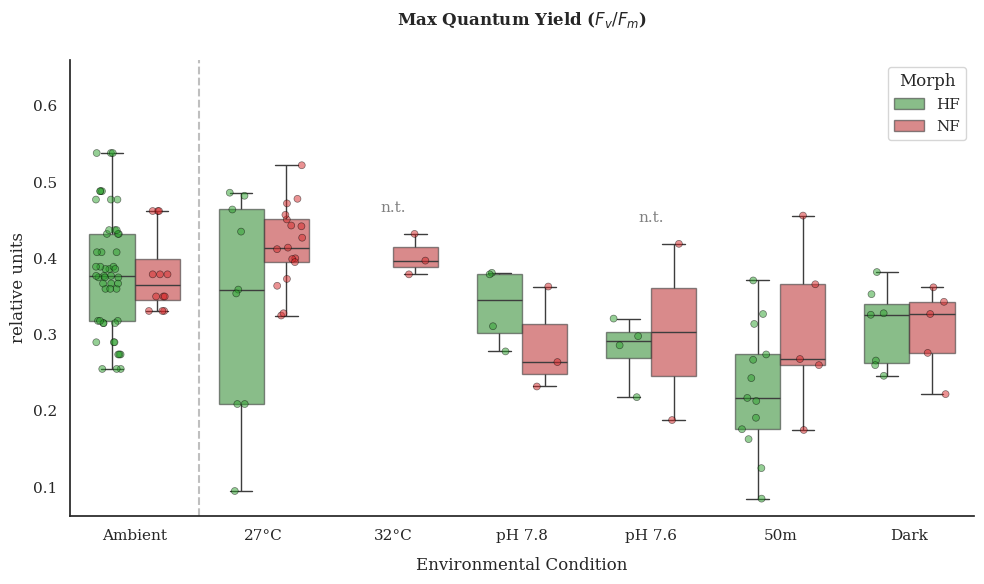

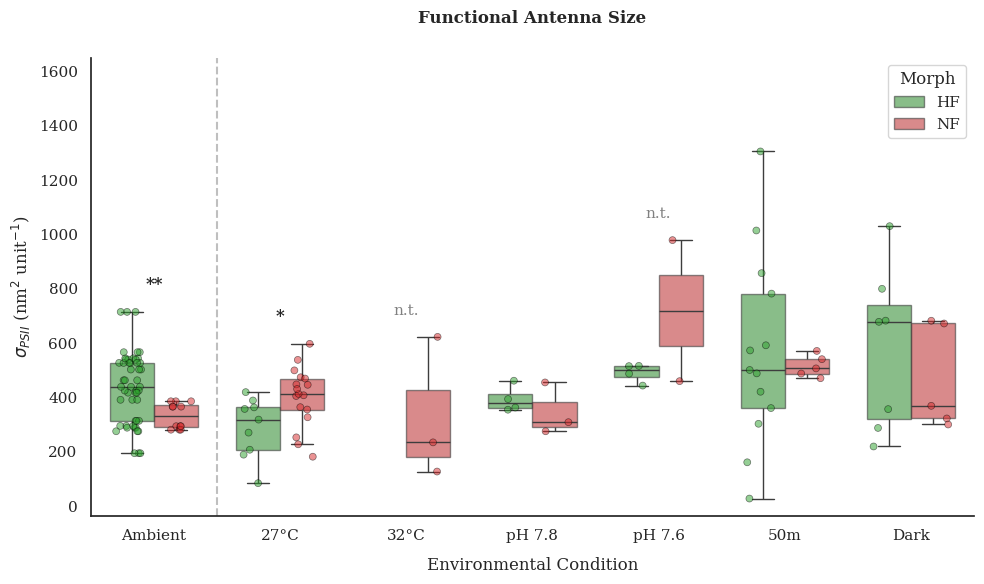

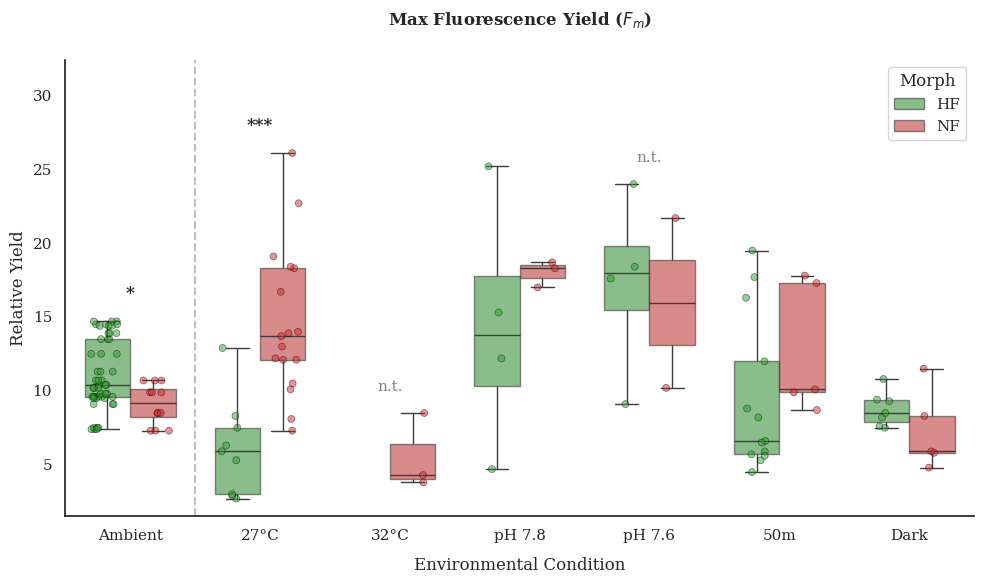

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="white", font="serif")

plot_configs = [
    {'col': 'FvFm', 'label': 'relative units', 'title': 'Max Quantum Yield ($F_v/F_m$)'},
    {'col': 'Sigma', 'label': r'$\sigma_{PSII}$ (nm$^{2}$ unit$^{-1}$)', 'title': 'Functional Antenna Size'},
    {'col': 'Fm', 'label': 'Relative Yield', 'title': 'Max Fluorescence Yield ($F_m$)'}
]

for config in plot_configs:
    metric_col = config['col']
    if 'fire_clean' not in globals() or metric_col not in fire_clean.columns:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))

    # Boxplot using global palette
    sns.boxplot(data=fire_clean, x='Condition', y=metric_col, hue='Morph',
                order=plot_order, hue_order=['HF', 'NF'], palette=variant_colors,
                ax=ax, width=0.7, boxprops=dict(alpha=0.6), showfliers=False)

    # Stripplot
    sns.stripplot(data=fire_clean, x='Condition', y=metric_col, hue='Morph',
                  order=plot_order, hue_order=['HF', 'NF'], palette=variant_colors,
                  ax=ax, dodge=True, size=global_marker_size, alpha=global_alpha,
                  jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)

    # Statistical Annotations and Limits
    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min
    ax.set_ylim(y_min, y_max + y_range * 0.2)

    for idx, cond in enumerate(plot_order):
        cond_data = fire_clean[fire_clean['Condition'] == cond]
        hf = cond_data[cond_data['Morph'] == 'HF'][metric_col].dropna()
        nf = cond_data[cond_data['Morph'] == 'NF'][metric_col].dropna()

        if len(hf) >= 3 and len(nf) >= 3:
            _, p1 = stats.shapiro(hf)
            _, p2 = stats.shapiro(nf)
            if p1 > 0.05 and p2 > 0.05:
                _, p_val = stats.ttest_ind(hf, nf, equal_var=False)
            else:
                _, p_val = stats.mannwhitneyu(hf, nf, alternative='two-sided')

            if p_val < 0.05:
                sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
                ax.text(idx, max(hf.max(), nf.max()) + (y_range * 0.05), sig_text,
                        ha='center', va='bottom', fontweight='bold', family='serif')
        else:
            # Place explicit 'n.t.' above groups where contrast is not tested due to N < 3
            highest_val = max(hf.max() if len(hf) > 0 else y_min, nf.max() if len(nf) > 0 else y_min)
            ax.text(idx, highest_val + (y_range * 0.05), 'n.t.',
                    ha='center', va='bottom', fontsize=11, color='gray', family='serif')

    ax.set_title(config['title'], fontweight='bold', loc='center', family='serif')
    ax.set_xlabel("Environmental Condition", labelpad=10, family='serif')
    ax.set_ylabel(config['label'], family='serif')
    ax.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)

    sns.despine()
    plt.tight_layout()

    # Export figures at 600 DPI as requested
    plt.savefig(f"FIRe_{metric_col}.svg", format='svg', dpi=600)
    plt.savefig(f"FIRe_{metric_col}.png", format='png', dpi=600)
    plt.show()

### Block 6: Reproducibility & Version Tracking
This block documents the specific software and library versions used to generate this analysis and the final figure.

In [8]:
import pandas as pd
import numpy as np
import scipy
import statsmodels
import matplotlib
import seaborn as sns
import sys

print("=== REPRODUCIBILITY REPORT ===")
print(f"Python version:      {sys.version.split()[0]}")
print(f"Pandas version:      {pd.__version__}")
print(f"NumPy version:       {np.__version__}")
print(f"SciPy version:       {scipy.__version__}")
print(f"Statsmodels version: {statsmodels.__version__}")
print(f"Matplotlib version:  {matplotlib.__version__}")
print(f"Seaborn version:     {sns.__version__}")
print("==============================")

=== REPRODUCIBILITY REPORT ===
Python version:      3.13.18
Pandas version:      2.2.3
NumPy version:       2.4.6
SciPy version:       1.16.3
Statsmodels version: 0.15.0
Matplotlib version:  3.10.0
Seaborn version:     0.13.2


ᵃ Parametric data are presented as Mean \u00B1 Standard Deviation (SD).
ᵇ Non-parametric data are presented as Median (Interquartile Range, IQR).

In [13]:
# ==============================================================================
# STANDARDIZED DESCRIPTIVE & INFERENTIAL TABLE (FIRe_TableS4_Summary.csv)
# ==============================================================================
import numpy as np
import pandas as pd
from scipy import stats
from google.colab import files

results_list = []
target_metrics = ['FvFm', 'Fm', 'Sigma']
conditions_list = ['Ambient', '27°C', '32°C', 'pH 7.8', 'pH 7.6', '50m', 'Dark']

for metric in target_metrics:
    if metric not in fire_clean.columns: continue
    for cond in conditions_list:
        sub = fire_clean[fire_clean['Condition'] == cond]
        hf = sub[sub['Morph'] == 'HF'][metric].dropna()
        nf = sub[sub['Morph'] == 'NF'][metric].dropna()

        n_hf = len(hf)
        n_nf = len(nf)

        # Standardize Summary as Mean ± SD [med: Median]
        hf_summary = f"{hf.mean():.4f} ± {hf.std():.4f} [med: {hf.median():.4f}]" if n_hf > 0 else "N/A"
        nf_summary = f"{nf.mean():.4f} ± {nf.std():.4f} [med: {nf.median():.4f}]" if n_nf > 0 else "N/A"

        test_used = 'n.t.'
        stat_val = np.nan
        p_val = np.nan
        sig = '-'
        effect_size = np.nan
        ci_str = 'N/A'

        if n_hf >= 3 and n_nf >= 3:
            _, p_sh_hf = stats.shapiro(hf)
            _, p_sh_nf = stats.shapiro(nf)

            if p_sh_hf > 0.05 and p_sh_nf > 0.05:
                test_used = "Welch's t-test"
                res_t = stats.ttest_ind(hf, nf, equal_var=False)
                stat_val = res_t.statistic
                p_val = res_t.pvalue

                # Cohen's d
                s_pool = np.sqrt(((n_hf - 1) * hf.var() + (n_nf - 1) * nf.var()) / (n_hf + n_nf - 2))
                effect_size = (hf.mean() - nf.mean()) / s_pool if s_pool != 0 else 0

                # 95% Confidence Interval
                mean_diff = hf.mean() - nf.mean()
                se_diff = np.sqrt(hf.var() / n_hf + nf.var() / n_nf)
                df_welch = ((hf.var() / n_hf + nf.var() / n_nf) ** 2) / (((hf.var() / n_hf) ** 2) / (n_hf - 1) + ((nf.var() / n_nf) ** 2) / (n_nf - 1))
                t_crit = stats.t.ppf(0.975, df=df_welch)
                margin = t_crit * se_diff
                ci_str = f"[{mean_diff - margin:.4f}, {mean_diff + margin:.4f}]"
            else:
                test_used = 'Mann-Whitney U'
                res_u = stats.mannwhitneyu(hf, nf, alternative='two-sided')
                stat_val = res_u.statistic
                p_val = res_u.pvalue

                # Rank-biserial correlation r
                effect_size = 1.0 - (2.0 * stat_val) / (n_hf * n_nf) if (n_hf * n_nf) != 0 else 0
                ci_str = 'N/A'

            sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'

        results_list.append({
            'Metric / Parameter': metric,
            'Condition / Treatment': cond,
            'N_HF': n_hf,
            'HF_Value': hf_summary,
            'N_NF': n_nf,
            'NF_Value': nf_summary,
            'Test_Used': test_used,
            'Test_Statistic': f"{stat_val:.4f}" if not np.isnan(stat_val) else 'N/A',
            'p_value': f"{p_val:.4f}" if not np.isnan(p_val) else 'n.t.',
            'Significance': sig,
            'Effect_Size': f"{effect_size:.4f}" if not np.isnan(effect_size) else 'N/A',
            '95%_CI': ci_str
        })

df_table_s4 = pd.DataFrame(results_list)
df_table_s4.to_csv('FIRe_TableS4_Summary.csv', index=False)

print("### COMPREHENSIVE STATISTICAL SUMMARY TABLE (S4)")
print(df_table_s4.to_markdown(index=False))

# Trigger downloads
files.download('FIRe_removed_samples_audit.csv')
files.download('FIRe_TableS4_Summary.csv')


### COMPREHENSIVE STATISTICAL SUMMARY TABLE (S4)
| Metric / Parameter   | Condition / Treatment   |   N_HF | HF_Value                            |   N_NF | NF_Value                            | Test_Used      | Test_Statistic   | p_value   | Significance   | Effect_Size   | 95%_CI                |
|:---------------------|:------------------------|-------:|:------------------------------------|-------:|:------------------------------------|:---------------|:-----------------|:----------|:---------------|:--------------|:----------------------|
| FvFm                 | Ambient                 |     51 | 0.3815 ± 0.0761 [med: 0.3770]       |     12 | 0.3805 ± 0.0523 [med: 0.3645]       | Mann-Whitney U | 315.0000         | 0.8816    | ns             | -0.0294       | N/A                   |
| FvFm                 | 27°C                    |      9 | 0.3437 ± 0.1417 [med: 0.3590]       |     17 | 0.4178 ± 0.0525 [med: 0.4140]       | Welch's t-test | -1.5145          | 0.1635    | ns      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>